# Modèles semi-supervisés : A (supervisé) vs B (labels faibles) vs C (labels faibles + augmentation)

**Projet ForestFireDetection** – Détection précoce de feux de forêt (fumée / feu)

Question : les ~12 900 labels faibles issus du clustering (`unsupervised_analysis.ipynb`) améliorent-ils un CNN
entraîné avec seulement **688 images labellisées** ?

| Modèle | Entraînement |
|---|---|
| **A** – supervisé | 688 images labellisées |
| **B** – semi-supervisé | phase 1 : 688 labellisées + labels faibles ; phase 2 : ajustement sur les 688 (taux d'apprentissage ÷ 10) |
| **C** – semi-supervisé + augmentation | comme B, avec augmentation des images labellisées en phase 1 |

**Architecture commune** : ConvNeXt-Tiny pré-entraîné ImageNet, dernier stage (`features[7]`) dégelé,
tête MLP à **2 sorties** (fumée, feu), perte `BCEWithLogitsLoss` avec `pos_weight`, précision mixte (AMP).

**Protocole**
- **Choix du modèle** (arrêt anticipé, Optuna) : **AP moyenne** fumée + feu sur val. L'AP résume toute la courbe
  précision-rappel, ne dépend d'aucun seuil et ne peut pas être gonflée en répondant « oui » à tout.
- **Seuils de décision** : choisis sur val pour maximiser le **F2** (le rappel compte deux fois plus : rater un feu
  coûte plus cher qu'une fausse alerte), puis figés.
- **Test** : utilisé **une seule fois**, à la fin, en version complète et « propre » (sans quasi-doublon du train).
- **Rapport** : d'abord l'**alerte** (fumée OU feu, ce que reçoit l'opérateur), puis fumée et feu, avec une
  référence « **toujours oui** » et les **courbes précision-rappel**.

**Traçabilité (MLflow)** : hyperparamètres, métriques par époque, jeux de données utilisés, commit git, empreinte
de `uv.lock`, figures, et chaque modèle enregistré dans le **Model Registry** avec la signature de ses entrées /
sorties.

## 1. Imports et configuration

In [ ]:
import sys
import time
import warnings
from pathlib import Path

# Ajout de la racine du projet au chemin Python pour importer src/
ROOT = Path.cwd().resolve()
sys.path.append(str(ROOT.parent if ROOT.name == "notebooks" else ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import optuna
import mlflow
from mlflow import MlflowClient
from optuna.visualization import matplotlib as optuna_mpl
from sklearn.metrics import precision_recall_curve

from src.config import (
    ROOT_DIR, WEAK_LABELS_PATH, IMAGE_CACHE_PATH, IMAGE_CACHE_INDEX_PATH, MODELS_DIR, RESULTS_DIR,
    MODEL_COMPARISON_PATH, CATEGORY_ORDER, TASKS, RANDOM_STATE, describe_device,
)
from src.cnn import ImageSet, build_model, fit, load_batch, predict
from src.metrics import bootstrap_ci, evaluate_predictions, tune_thresholds
from src.tracking import log_and_register_model, reproducibility_tags, setup_mlflow

MODELS_DIR.mkdir(exist_ok=True)
describe_device()

# Fonctions matplotlib d'Optuna marquées expérimentales dans la doc : avertissement masqué
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Paramètres propres à ce notebook
N_TRIALS = 20                    # essais Optuna (modèle A)
MAX_EPOCHS_A, PATIENCE_A = 30, 6                 # modèle A et phase 2 de B / C
MAX_EPOCHS_PHASE1, PATIENCE_PHASE1 = 15, 3       # phase 1 de B / C (labels faibles, ~14 000 images)
PHASE2_LR_FACTOR = 0.1           # taux d'apprentissage réduit pour l'ajustement final (comme le P7)
N_AUG_COPIES = 5                 # modèle C : copies augmentées de chaque image labellisée par époque
REGISTRY_PREFIX = "forest_fire_convnext"         # noms dans le Model Registry : <prefix>_A, _B, _C

c:\Users\faiza\Formation_IA\ForestFireDetection\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch 2.14.1+cu130 | appareil : cuda
GPU : NVIDIA GeForce RTX 5070 Laptop GPU | mémoire : 7.9 Go
DataLoader : batch 64, 0 workers, pin_memory=True, décodage JPEG réduit=True


### Suivi MLflow

Expérience `semi_supervised_models` :
- run `optuna_model_A` (parent) avec un run enfant par essai ;
- un run par modèle final (`model_A`, `model_B`, `model_C`), chacun enregistré dans le **Model Registry**.

Interface : `uv run mlflow server --port 5000` depuis la racine du projet, puis http://localhost:5000
(onglet *Models* pour le registre).

In [ ]:
setup_mlflow("semi_supervised_models")
repro_tags = reproducibility_tags()
display(pd.Series(repro_tags, name="reproductibilité").to_frame())
if repro_tags["git_dirty"] == "True":
    print("Attention : modifications non commitées – le commit enregistré ne suffit pas à reproduire le run.")

MLflow : expérience « semi_supervised_models » | base : sqlite:///C:/Users/faiza/Formation_IA/ForestFireDetection/mlflow.db


,reproductibilité
git_commit,8515cfddb7878b7f7bf56829706474df7b7b982a
git_branch,feature/semi-supervised-models
git_dirty,True
uv_lock_sha256,3d6569968dfaa73c
python,3.11.15
torch,2.14.1+cu130
torchvision,0.29.1+cu130


Attention : modifications non commitées – le commit enregistré ne suffit pas à reproduire le run.


## 2. Données

- Images : cache 224×224 (`image_cache.ipynb`), normalisées sur le GPU.
- Labels : vrais labels pour les images labellisées, val et test ; **labels faibles** (K-Means K=64) pour les
  autres images du train.

In [ ]:
images = np.load(IMAGE_CACHE_PATH, mmap_mode="r")
df = pd.read_csv(WEAK_LABELS_PATH).merge(pd.read_csv(IMAGE_CACHE_INDEX_PATH)[["image_id", "position"]],
                                         on="image_id", how="left")
assert df["position"].notna().all()

is_train = df["final_split"] == "train"
labeled = df[is_train & df["is_labeled"].eq(True)]
weak = df[is_train & df["is_labeled"].ne(True) & df["has_weak_label"].eq(True)]
val = df[df["final_split"] == "val"]
test = df[df["final_split"] == "test"].reset_index(drop=True)


def make_set(frame, label_cols, augment=False):
    """ImageSet à partir d'un DataFrame (positions dans le cache + labels binaires)."""
    return ImageSet(frame["position"].to_numpy(), frame[label_cols].to_numpy().astype(int),
                    np.full(len(frame), augment))


def concat_sets(*sets):
    return ImageSet(np.concatenate([s.positions for s in sets]), np.concatenate([s.labels for s in sets]),
                    np.concatenate([s.augment for s in sets]))


labeled_set = make_set(labeled, TASKS)
weak_set = make_set(weak, ["weak_smoke", "weak_fire"])
val_set = make_set(val, TASKS)
test_set = make_set(test, TASKS)

summary = pd.DataFrame({
    "images": [len(labeled_set), len(weak_set), len(val_set), len(test_set)],
    "fumée (%)": [100 * s.labels[:, 0].mean() for s in (labeled_set, weak_set, val_set, test_set)],
    "feu (%)": [100 * s.labels[:, 1].mean() for s in (labeled_set, weak_set, val_set, test_set)],
}, index=["train labellisé (vrais labels)", "train non labellisé (labels faibles)", "val", "test"])
display(summary.round(1))
print(f"Test propre : {test['test_clean'].sum()} images sur {len(test)}")

# Jeux de données enregistrés dans MLflow (identifiants d'images + labels) pour la traçabilité.
# Source : chemin relatif au projet (portable) ; avertissement MLflow sur l'interprétation du chemin masqué.
warnings.filterwarnings("ignore", message="The specified dataset source can be interpreted")
DATASET_SOURCE = WEAK_LABELS_PATH.relative_to(ROOT_DIR).as_posix()
mlflow_datasets = {
    "train_labeled": mlflow.data.from_pandas(labeled[["image_id"] + TASKS], source=DATASET_SOURCE,
                                             name="train_labeled"),
    "train_weak": mlflow.data.from_pandas(weak[["image_id", "weak_smoke", "weak_fire"]],
                                          source=DATASET_SOURCE, name="train_weak_labels"),
    "val": mlflow.data.from_pandas(val[["image_id"] + TASKS], source=DATASET_SOURCE, name="val"),
    "test": mlflow.data.from_pandas(test[["image_id", "test_clean"] + TASKS], source=DATASET_SOURCE,
                                    name="test"),
}

,images,fumée (%),feu (%)
train labellisé (vrais labels),688,49.0,27.3
train non labellisé (labels faibles),12912,50.5,24.3
val,3448,49.0,27.4
test,4306,48.3,25.9


Test propre : 2192 images sur 4306


## 3. Recherche d'hyperparamètres (Optuna) sur le modèle A

Comme dans le P7, les hyperparamètres sont optimisés sur le modèle **A** (le plus rapide à entraîner), puis
**réutilisés pour B et C** : la comparaison reste équitable.

- Échantillonneur **TPE** (graine fixe) et **MedianPruner** : un essai est arrêté si son AP sur val est sous la
  médiane des essais précédents au même nombre d'époques.
- Objectif : **AP moyenne sur val** (meilleure époque).
- Chaque essai est enregistré comme un **run enfant MLflow**.
- Barre de progression : nombre d'essais réalisés et meilleure AP obtenue.

In [ ]:
def objective(trial):
    params = {
        "lr_head": trial.suggest_float("lr_head", 1e-4, 3e-3, log=True),
        "lr_backbone": trial.suggest_float("lr_backbone", 1e-6, 3e-4, log=True),
        "hidden_dim": trial.suggest_categorical("hidden_dim", [256, 512, 1024]),
        "dropout": trial.suggest_float("dropout", 0.1, 0.5),
        "weight_decay": trial.suggest_float("weight_decay", 1e-5, 1e-2, log=True),
    }
    torch.manual_seed(RANDOM_STATE)                       # même initialisation de la tête pour chaque essai
    model = build_model(params["hidden_dim"], params["dropout"])

    def report(epoch, score):
        mlflow.log_metric("val_ap_mean", score, step=epoch)
        trial.report(score, epoch)
        if trial.should_prune():
            raise optuna.TrialPruned()

    mlflow.start_run(run_name=f"trial_{trial.number:02d}", nested=True)
    mlflow.log_params(params)
    status = "FAILED"
    try:
        best, history = fit(model, images, labeled_set, val_set, params["lr_backbone"], params["lr_head"],
                            params["weight_decay"], MAX_EPOCHS_A, PATIENCE_A, seed=RANDOM_STATE, on_epoch=report)
        mlflow.log_metrics({"best_val_ap_mean": best, "epochs": len(history)})
        status = "FINISHED"
        return best
    except optuna.TrialPruned:
        mlflow.set_tag("optuna_state", "pruned")
        status = "KILLED"
        raise
    finally:
        mlflow.end_run(status=status)
        torch.cuda.empty_cache()


study = optuna.create_study(
    direction="maximize", study_name="convnext_tiny_model_A",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=5),
)
t0 = time.time()
with mlflow.start_run(run_name="optuna_model_A") as optuna_run:
    mlflow.set_tags(repro_tags)
    mlflow.log_input(mlflow_datasets["train_labeled"], context="training")
    mlflow.log_input(mlflow_datasets["val"], context="validation")
    mlflow.log_params({"n_trials": N_TRIALS, "max_epochs": MAX_EPOCHS_A, "patience": PATIENCE_A,
                       "objective": "val_ap_mean", "sampler": "TPE", "pruner": "MedianPruner",
                       "backbone": "convnext_tiny_imagenet1k_v1", "random_state": RANDOM_STATE})
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)   # barre : essais + meilleure AP
    mlflow.log_params({f"best_{k}": v for k, v in study.best_params.items()})
    mlflow.log_metric("best_val_ap_mean", study.best_value)
print(f"\nRecherche terminée en {(time.time() - t0) / 60:.0f} min")
best_params = study.best_params
display(pd.Series(best_params, name="meilleurs hyperparamètres").to_frame())
display(study.trials_dataframe()[["number", "state", "value", "params_lr_head", "params_lr_backbone",
                                   "params_hidden_dim", "params_dropout", "params_weight_decay"]].round(5))

c:\Users\faiza\Formation_IA\ForestFireDetection\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
Best trial: 14. Best value: 0.92847: 100%|██████████| 20/20 [24:41<00:00, 74.10s/it]


Recherche terminée en 25 min


,meilleurs hyperparamètres
lr_head,0.000465
lr_backbone,0.000292
hidden_dim,256.000000
dropout,0.174058
weight_decay,0.000069


,number,state,value,params_lr_head,params_lr_backbone,params_hidden_dim,params_dropout,params_weight_decay
0,0,COMPLETE,0.92380,0.00036,0.00023,256,0.16240,0.00001
1,1,COMPLETE,0.90489,0.00190,0.00003,1024,0.43298,0.00004
2,2,COMPLETE,0.90437,0.00019,0.00000,512,0.21649,0.00068
3,3,COMPLETE,0.90394,0.00016,0.00001,1024,0.17987,0.00035
4,4,COMPLETE,0.90479,0.00075,0.00000,256,0.47955,0.00789
5,5,COMPLETE,0.90454,0.00156,0.00001,512,0.14882,0.00031
6,6,COMPLETE,0.91247,0.00011,0.00018,512,0.30803,0.00044
7,7,COMPLETE,0.91740,0.00019,0.00025,512,0.33916,0.00583
8,8,PRUNED,0.87817,0.00014,0.00000,1024,0.20854,0.00306
9,9,PRUNED,0.90070,0.00034,0.00000,1024,0.12982,0.00913


### Visualisations de la recherche

- **Coordonnées parallèles** (« toile d'araignée ») : chaque ligne est un essai, chaque axe un hyperparamètre,
  la couleur indique l'AP obtenue. Version interactive (plotly, fichier HTML dans `results/` et MLflow) et version
  statique ci-dessous (matplotlib).
- **Importance des hyperparamètres** et **historique de l'optimisation** (HTML).

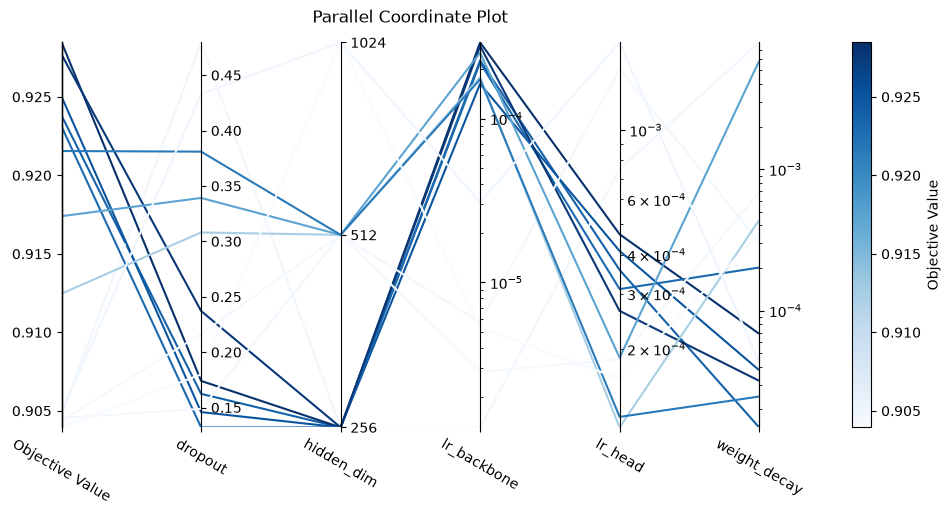

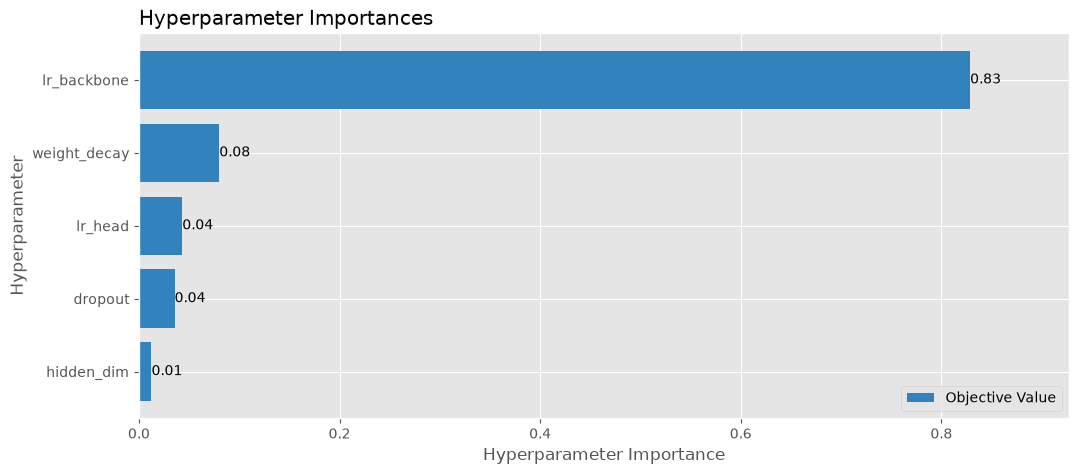

In [ ]:
html_figures = {
    "optuna_parallel_coordinate.html": optuna.visualization.plot_parallel_coordinate(study),
    "optuna_param_importances.html": optuna.visualization.plot_param_importances(study),
    "optuna_history.html": optuna.visualization.plot_optimization_history(study),
}
for name, fig in html_figures.items():
    fig.write_html(RESULTS_DIR / name, include_plotlyjs="cdn", auto_open=False)   # léger, plotly.js via CDN

png_figures = {
    "optuna_parallel_coordinate.png": optuna_mpl.plot_parallel_coordinate,
    "optuna_param_importances.png": optuna_mpl.plot_param_importances,
}
for name, plot_fn in png_figures.items():
    ax = plot_fn(study)
    ax.figure.set_size_inches(12, 5)
    ax.figure.savefig(RESULTS_DIR / name, dpi=100, bbox_inches="tight")
    plt.show()

with mlflow.start_run(run_id=optuna_run.info.run_id):
    for name in list(html_figures) + list(png_figures):
        mlflow.log_artifact(str(RESULTS_DIR / name), artifact_path="optuna")

## 4. Entraînement des modèles finaux

Les trois modèles utilisent les **mêmes hyperparamètres** (meilleurs de la recherche) et la même graine.
Chaque run MLflow enregistre ses paramètres, ses jeux de données, l'AP de val à chaque époque et les tags de
reproductibilité. Barres de progression : époques de chaque phase (perte, AP val, meilleure AP) et lots de
l'époque en cours.

In [ ]:
def train_model(name, phases, datasets):
    """Entraîne un modèle par phases successives ; un run MLflow par modèle. Renvoie (modèle, run_id, historique)."""
    torch.manual_seed(RANDOM_STATE)
    model = build_model(best_params["hidden_dim"], best_params["dropout"])
    history = []
    t0 = time.time()
    with mlflow.start_run(run_name=f"model_{name}") as run:
        mlflow.set_tags({**repro_tags, "model_variant": name})
        for key in datasets:
            mlflow.log_input(mlflow_datasets[key], context="training")
        mlflow.log_input(mlflow_datasets["val"], context="validation")
        mlflow.log_params({**best_params, "model": name, "backbone": "convnext_tiny_imagenet1k_v1",
                           "random_state": RANDOM_STATE, "early_stopping_metric": "val_ap_mean",
                           **{f"{p['name']}_images": len(p["train"]) for p in phases},
                           **{f"{p['name']}_max_epochs": p["max_epochs"] for p in phases},
                           **{f"{p['name']}_lr_factor": p.get("lr_factor", 1.0) for p in phases}})
        for phase in phases:
            factor = phase.get("lr_factor", 1.0)
            best, hist = fit(model, images, phase["train"], val_set,
                             best_params["lr_backbone"] * factor, best_params["lr_head"] * factor,
                             best_params["weight_decay"], phase["max_epochs"], phase["patience"], seed=RANDOM_STATE,
                             progress=True, desc=f"modèle {name} – {phase['name']}")
            for h in hist:
                mlflow.log_metrics({f"{phase['name']}_val_ap_mean": h["val_ap_mean"],
                                    f"{phase['name']}_train_loss": h["train_loss"]}, step=h["epoch"])
            history += [{**h, "phase": phase["name"]} for h in hist]
            print(f"modèle {name} | {phase['name']} : {len(hist)} époques, meilleure AP val = {best:.4f}")
        torch.save(model.state_dict(), MODELS_DIR / f"model_{name}.pt")
        mlflow.log_param("weights_path", f"models/model_{name}.pt")
        print(f"modèle {name} entraîné en {(time.time() - t0) / 60:.1f} min")
        return model, run.info.run_id, pd.DataFrame(history)


labeled_aug = concat_sets(*[make_set(labeled, TASKS, augment=True) for _ in range(N_AUG_COPIES)])
phase2 = {"name": "phase2", "train": labeled_set, "lr_factor": PHASE2_LR_FACTOR,
          "max_epochs": MAX_EPOCHS_A, "patience": PATIENCE_A}
plan = {
    "A": ([{"name": "phase1", "train": labeled_set, "max_epochs": MAX_EPOCHS_A, "patience": PATIENCE_A}],
          ["train_labeled"]),
    "B": ([{"name": "phase1", "train": concat_sets(labeled_set, weak_set),
            "max_epochs": MAX_EPOCHS_PHASE1, "patience": PATIENCE_PHASE1}, phase2],
          ["train_labeled", "train_weak"]),
    "C": ([{"name": "phase1", "train": concat_sets(labeled_set, weak_set, labeled_aug),
            "max_epochs": MAX_EPOCHS_PHASE1, "patience": PATIENCE_PHASE1}, phase2],
          ["train_labeled", "train_weak"]),
}
display(pd.DataFrame({m: {p["name"]: len(p["train"]) for p in phases} for m, (phases, _) in plan.items()})
          .rename_axis("images par phase"))

models, run_ids, histories = {}, {}, {}
for name, (phases, datasets) in plan.items():
    models[name], run_ids[name], histories[name] = train_model(name, phases, datasets)
    torch.cuda.empty_cache()

,A,B,C
images par phase,,,
phase1,688.0,13600,17040
phase2,NaN,688,688


modèle A – phase1:  43%|████▎     | 13/30 [00:58<01:16,  4.49s/époque, ap_val=0.9141, meilleure=0.9285, perte=0.0214]


modèle A | phase1 : 14 époques, meilleure AP val = 0.9285
modèle A entraîné en 1.0 min


modèle B – phase1:  40%|████      | 6/15 [02:25<03:38, 24.29s/époque, ap_val=0.7587, meilleure=0.7971, perte=0.0413]


modèle B | phase1 : 7 époques, meilleure AP val = 0.7971


modèle B – phase2: 100%|██████████| 30/30 [02:06<00:00,  4.21s/époque, ap_val=0.8440, meilleure=0.8440, perte=0.0253]


modèle B | phase2 : 30 époques, meilleure AP val = 0.8440
modèle B entraîné en 4.6 min


modèle C – phase1:  33%|███▎      | 5/15 [02:35<05:11, 31.17s/époque, ap_val=0.8021, meilleure=0.8168, perte=0.0417]


modèle C | phase1 : 6 époques, meilleure AP val = 0.8168


modèle C – phase2:  90%|█████████ | 27/30 [01:58<00:13,  4.38s/époque, ap_val=0.8610, meilleure=0.8619, perte=0.0149]


modèle C | phase2 : 28 époques, meilleure AP val = 0.8619
modèle C entraîné en 4.6 min


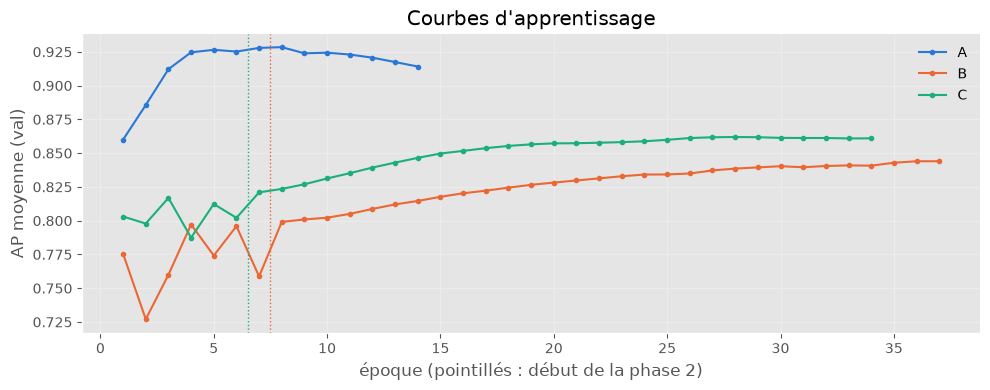

In [ ]:
# Courbes d'apprentissage : AP moyenne sur val à chaque époque
colors = {"A": "#2a78d6", "B": "#eb6834", "C": "#1baf7a"}
fig, ax = plt.subplots(figsize=(10, 4))
for name, hist in histories.items():
    hist = hist.reset_index(drop=True)
    ax.plot(hist.index + 1, hist["val_ap_mean"], marker="o", markersize=3, color=colors[name], label=name)
    if (hist["phase"] == "phase2").any():
        ax.axvline(hist.index[hist["phase"] == "phase2"][0] + 0.5, color=colors[name], linestyle=":", linewidth=1)
ax.set_xlabel("époque (pointillés : début de la phase 2)")
ax.set_ylabel("AP moyenne (val)")
ax.set_title("Courbes d'apprentissage")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "learning_curves.png", dpi=100)
plt.show()

## 5. Seuils de décision et résultats sur val

Pour chaque modèle, le seuil de chaque tâche est choisi sur **val** pour maximiser le F2, puis **figé** pour le
test. La ligne « **toujours oui** » donne le score d'un détecteur qui déclare fumée et feu sur toutes les images :
un modèle utile doit faire nettement mieux.

In [ ]:
ALWAYS_YES = "toujours oui (référence)"
REPORT_COLS = ["alert_f2", "alert_recall", "alert_precision", "alert_ap", "f2_mean", "ap_mean",
               "smoke_f2", "smoke_recall", "smoke_precision", "smoke_ap", "smoke_roc_auc",
               "fire_f2", "fire_recall", "fire_precision", "fire_ap", "fire_roc_auc"]

probs_val, thresholds = {}, {}
rows = [{"modèle": ALWAYS_YES, **evaluate_predictions(val_set.labels, np.ones(val_set.labels.shape), [0.5, 0.5])}]
for name, model in models.items():
    probs_val[name] = predict(model, images, val_set.positions)
    thresholds[name] = tune_thresholds(val_set.labels, probs_val[name])
    rows.append({"modèle": name, "seuil fumée": thresholds[name][0], "seuil feu": thresholds[name][1],
                 **evaluate_predictions(val_set.labels, probs_val[name], thresholds[name])})
val_results = pd.DataFrame(rows).set_index("modèle")
display(val_results[["seuil fumée", "seuil feu"] + REPORT_COLS].round(3))
best_model = val_results.drop(index=ALWAYS_YES)["ap_mean"].idxmax()
print(f"Meilleur modèle sur val (AP moyenne) : {best_model}")

,seuil fumée,seuil feu,alert_f2,alert_recall,alert_precision,alert_ap,f2_mean,ap_mean,smoke_f2,smoke_recall,smoke_precision,smoke_ap,smoke_roc_auc,fire_f2,fire_recall,fire_precision,fire_ap,fire_roc_auc
modèle,,,,,,,,,,,,,,,,,,
toujours oui (référence),NaN,NaN,0.857,1.000,0.546,0.546,0.741,0.382,0.827,1.000,0.490,0.490,0.500,0.654,1.000,0.274,0.274,0.500
A,0.05,0.07,0.880,0.897,0.818,0.949,0.885,0.928,0.852,0.885,0.740,0.923,0.910,0.918,0.961,0.780,0.934,0.973
B,0.05,0.05,0.837,0.842,0.821,0.885,0.824,0.844,0.824,0.841,0.760,0.863,0.863,0.824,0.841,0.760,0.825,0.930
C,0.05,0.05,0.813,0.813,0.810,0.892,0.815,0.862,0.823,0.836,0.777,0.877,0.866,0.806,0.818,0.760,0.847,0.936


Meilleur modèle sur val (AP moyenne) : A


## 6. Évaluation finale sur le test (utilisé une seule fois)

- **Test complet** (4 306 images) et **test propre** (images sans quasi-doublon dans le train).
- Intervalle de confiance à 95 % du F2 moyen par bootstrap (1 000 rééchantillonnages, seuils figés).

In [ ]:
clean = test["test_clean"].eq(True).to_numpy()
subsets = {"test complet": np.ones(len(test), dtype=bool), "test propre": clean}
rows, probs_test = [], {}
for subset, mask in subsets.items():
    rows.append({"modèle": ALWAYS_YES, "jeu": subset,
                 **evaluate_predictions(test_set.labels[mask], np.ones((mask.sum(), 2)), [0.5, 0.5])})
for name, model in models.items():
    probs_test[name] = predict(model, images, test_set.positions)
    for subset, mask in subsets.items():
        y, p = test_set.labels[mask], probs_test[name][mask]
        low, high = bootstrap_ci(y, p, thresholds[name], seed=RANDOM_STATE)
        rows.append({"modèle": name, "jeu": subset, "F2 IC95 bas": low, "F2 IC95 haut": high,
                     **evaluate_predictions(y, p, thresholds[name])})
test_results = pd.DataFrame(rows)
for subset in subsets:
    print(f"\n{subset}")
    display(test_results[test_results["jeu"] == subset].set_index("modèle")
            [["F2 IC95 bas", "F2 IC95 haut"] + REPORT_COLS].round(3))


test complet


,F2 IC95 bas,F2 IC95 haut,alert_f2,alert_recall,alert_precision,alert_ap,f2_mean,ap_mean,smoke_f2,smoke_recall,smoke_precision,smoke_ap,smoke_roc_auc,fire_f2,fire_recall,fire_precision,fire_ap,fire_roc_auc
modèle,,,,,,,,,,,,,,,,,,
toujours oui (référence),NaN,NaN,0.852,1.000,0.534,0.534,0.730,0.371,0.824,1.000,0.483,0.483,0.500,0.636,1.000,0.259,0.259,0.500
A,0.895,0.911,0.910,0.940,0.810,0.963,0.903,0.945,0.891,0.935,0.752,0.930,0.932,0.914,0.942,0.818,0.960,0.980
B,0.830,0.852,0.858,0.870,0.814,0.917,0.841,0.879,0.833,0.861,0.739,0.871,0.877,0.849,0.863,0.797,0.888,0.946
C,0.840,0.862,0.857,0.868,0.814,0.925,0.852,0.894,0.837,0.861,0.751,0.878,0.881,0.867,0.884,0.804,0.909,0.954



test propre


,F2 IC95 bas,F2 IC95 haut,alert_f2,alert_recall,alert_precision,alert_ap,f2_mean,ap_mean,smoke_f2,smoke_recall,smoke_precision,smoke_ap,smoke_roc_auc,fire_f2,fire_recall,fire_precision,fire_ap,fire_roc_auc
modèle,,,,,,,,,,,,,,,,,,
toujours oui (référence),NaN,NaN,0.897,1.000,0.635,0.635,0.807,0.474,0.878,1.000,0.590,0.590,0.500,0.737,1.000,0.359,0.359,0.500
A,0.907,0.927,0.940,0.967,0.845,0.982,0.917,0.958,0.927,0.965,0.799,0.954,0.943,0.907,0.934,0.815,0.963,0.972
B,0.844,0.870,0.898,0.912,0.844,0.945,0.857,0.897,0.879,0.905,0.788,0.903,0.878,0.836,0.851,0.780,0.891,0.924
C,0.863,0.888,0.904,0.919,0.849,0.955,0.876,0.912,0.884,0.910,0.793,0.912,0.886,0.868,0.892,0.784,0.913,0.936


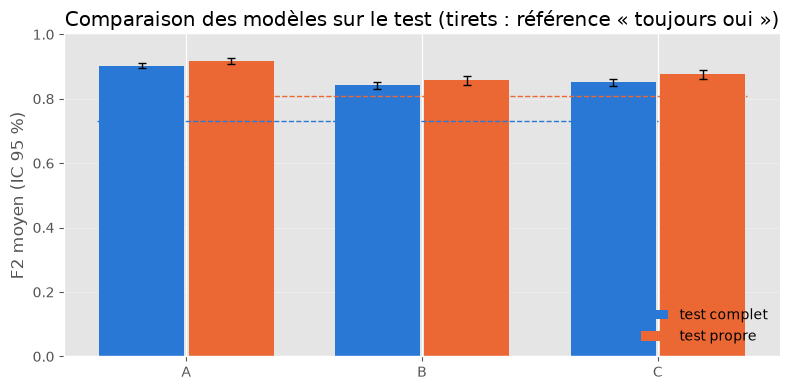

In [ ]:
# F2 moyen par modèle avec intervalle de confiance, test complet vs test propre
fig, ax = plt.subplots(figsize=(8, 4))
width = 0.38
for i, (subset, color) in enumerate([("test complet", "#2a78d6"), ("test propre", "#eb6834")]):
    sub = test_results[test_results["jeu"] == subset].set_index("modèle")
    x = np.arange(len(models)) + (i - 0.5) * width
    ax.bar(x, sub.loc[list(models), "f2_mean"], width - 0.02, color=color, label=subset)
    ax.errorbar(x, sub.loc[list(models), "f2_mean"],
                yerr=[sub.loc[list(models), "f2_mean"] - sub.loc[list(models), "F2 IC95 bas"],
                      sub.loc[list(models), "F2 IC95 haut"] - sub.loc[list(models), "f2_mean"]],
                fmt="none", ecolor="black", capsize=3, linewidth=1)
    ax.hlines(sub.loc[ALWAYS_YES, "f2_mean"], x.min() - width / 2, x.max() + width / 2, colors=color,
              linestyles="--", linewidth=1)
ax.set_xticks(np.arange(len(models)), list(models))
ax.set_ylabel("F2 moyen (IC 95 %)")
ax.set_ylim(0, 1)
ax.set_title("Comparaison des modèles sur le test (tirets : référence « toujours oui »)")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "model_comparison.png", dpi=100)
plt.show()

### Courbes précision-rappel (test complet)

Chaque courbe montre le compromis entre rappel (feux détectés) et précision (alertes justes) quand on fait varier
le seuil. Le **point** marque le seuil retenu sur val. La ligne horizontale grise est la précision du « toujours oui ».

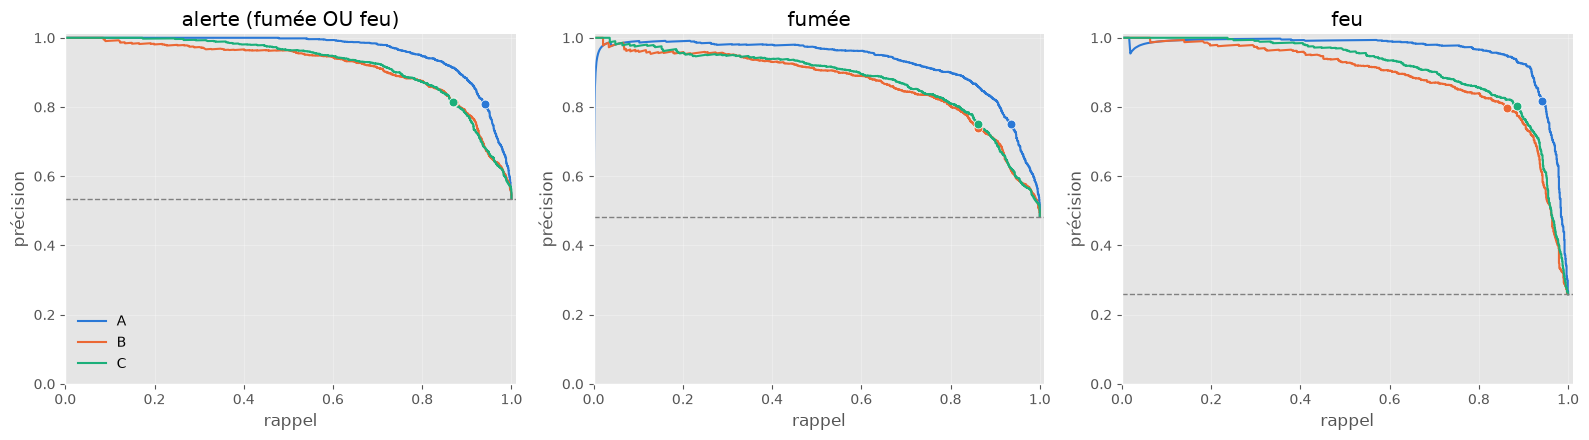

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
targets = {"alerte (fumée OU feu)": None, "fumée": 0, "feu": 1}
for ax, (title, j) in zip(axes, targets.items()):
    y_true = test_set.labels.max(axis=1) if j is None else test_set.labels[:, j]
    for name in models:
        score = probs_test[name].max(axis=1) if j is None else probs_test[name][:, j]
        precision, recall, _ = precision_recall_curve(y_true, score)
        ax.plot(recall, precision, color=colors[name], label=name, linewidth=1.5)
        # Point de fonctionnement : prédiction aux seuils retenus
        pred = (probs_test[name] >= thresholds[name]).astype(int)
        pred = pred.max(axis=1) if j is None else pred[:, j]
        tp = ((pred == 1) & (y_true == 1)).sum()
        ax.scatter(tp / y_true.sum(), tp / max(pred.sum(), 1), color=colors[name], s=40, zorder=3,
                   edgecolor="white")
    ax.axhline(y_true.mean(), color="gray", linestyle="--", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("rappel")
    ax.set_ylabel("précision")
    ax.set_xlim(0, 1.01), ax.set_ylim(0, 1.01)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.3)
axes[0].legend(frameon=False, loc="lower left")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "precision_recall_curves.png", dpi=100)
plt.show()

### Détail par source et matrice de confusion (test complet)

In [ ]:
rows = []
for name in models:
    for src, g in test.groupby("source"):
        idx = g.index.to_numpy()
        metrics = evaluate_predictions(test_set.labels[idx], probs_test[name][idx], thresholds[name])
        rows.append({"modèle": name, "source": src, "F2 alerte": metrics["alert_f2"], "F2 moyen": metrics["f2_mean"]})
display(pd.DataFrame(rows).pivot(index="source", columns="modèle", values=["F2 alerte", "F2 moyen"]).round(3))


def to_category(pred):
    return np.select([(pred[:, 0] == 1) & (pred[:, 1] == 1), pred[:, 1] == 1, pred[:, 0] == 1],
                     ["fire_and_smoke", "fire_only", "smoke_only"], "none")


pred_best = (probs_test[best_model] >= thresholds[best_model]).astype(int)
confusion = pd.crosstab(test["category"], to_category(pred_best), rownames=["réel"], colnames=["prédit"])
print(f"Matrice de confusion en 4 catégories – modèle {best_model} (meilleur sur val), test complet")
display(confusion.reindex(index=CATEGORY_ORDER, columns=CATEGORY_ORDER, fill_value=0))

F2 alerte               F2 moyen              
modèle                A      B      C        A      B      C
source                                                      
AoF               0.844  0.816  0.812    0.880  0.860  0.852
PublicDataset     0.905  0.727  0.710    0.856  0.759  0.748
WEB               0.944  0.901  0.904    0.920  0.852  0.871

Matrice de confusion en 4 catégories – modèle A (meilleur sur val), test complet


prédit,smoke_only,fire_only,fire_and_smoke,none
réel,,,,
smoke_only,938,3,125,120
fire_only,5,40,167,8
fire_and_smoke,41,2,841,11
none,401,36,70,1498


## 7. Enregistrement : métriques, artefacts et Model Registry

Pour chaque modèle :
- métriques de val, du test complet et du test propre dans son run ;
- modèle enregistré dans le **Model Registry** (`forest_fire_convnext_A`, `_B`, `_C`) :
  entrée = image normalisée `(n, 3, 224, 224)` float32, sortie = probabilités `(n, 2)` [fumée, feu] ;
  seuils de décision et scores ajoutés en tags de la version ;
- l'alias **`champion`** désigne la version du meilleur modèle sur val.

In [ ]:
comparison = pd.concat([val_results.reset_index().assign(jeu="val"), test_results], ignore_index=True)
comparison.to_csv(MODEL_COMPARISON_PATH, index=False)

# Exemple d'entrée réel (une image de val normalisée) pour la signature du modèle
input_example = load_batch(images, val_set.positions[:1], device=torch.device("cpu")).numpy().astype(np.float32)

client = MlflowClient()
registry = {}
for name, run_id in run_ids.items():
    with mlflow.start_run(run_id=run_id):
        mlflow.log_input(mlflow_datasets["test"], context="testing")
        mlflow.log_params({"threshold_smoke": float(thresholds[name][0]), "threshold_fire": float(thresholds[name][1])})
        val_metrics = val_results.loc[name, REPORT_COLS]
        mlflow.log_metrics({f"val_{k}": float(v) for k, v in val_metrics.items() if not np.isnan(v)})
        for _, r in test_results[test_results["modèle"] == name].iterrows():
            prefix = "test" if r["jeu"] == "test complet" else "test_clean"
            metrics = {k: r[k] for k in REPORT_COLS}
            metrics.update({"f2_mean_ci_low": r["F2 IC95 bas"], "f2_mean_ci_high": r["F2 IC95 haut"]})
            mlflow.log_metrics({f"{prefix}_{k}": float(v) for k, v in metrics.items() if not np.isnan(v)})
        mlflow.log_artifact(str(MODEL_COMPARISON_PATH))
        for fig_name in ["learning_curves.png", "model_comparison.png", "precision_recall_curves.png"]:
            mlflow.log_artifact(str(RESULTS_DIR / fig_name), artifact_path="figures")

        registered_name = f"{REGISTRY_PREFIX}_{name}"
        test_full = test_results[(test_results["modèle"] == name) & (test_results["jeu"] == "test complet")].iloc[0]
        _, version = log_and_register_model(
            models[name], registered_name, input_example, thresholds[name],
            tags={"variant": name, "val_ap_mean": f"{val_results.loc[name, 'ap_mean']:.4f}",
                  "test_alert_f2": f"{test_full['alert_f2']:.4f}", "test_f2_mean": f"{test_full['f2_mean']:.4f}",
                  "git_commit": repro_tags["git_commit"]},
        )
        registry[name] = (registered_name, version)

champion_name, champion_version = registry[best_model]
client.set_registered_model_alias(champion_name, "champion", champion_version)
display(pd.DataFrame(registry, index=["modèle enregistré", "version"]).T)
print(f"Alias « champion » → {champion_name} version {champion_version}")

c:\Users\faiza\Formation_IA\ForestFireDetection\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/13 16:41:07 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute ar

,modèle enregistré,version
A,forest_fire_convnext_A,1
B,forest_fire_convnext_B,1
C,forest_fire_convnext_C,1


Alias « champion » → forest_fire_convnext_A version 1


In [ ]:
# Vérification : le modèle champion rechargé depuis le registre redonne les mêmes probabilités
reloaded = mlflow.pytorch.load_model(f"models:/{champion_name}@champion").eval()
with torch.no_grad():
    reloaded_probs = reloaded(torch.from_numpy(input_example)).numpy()
direct_probs = predict(models[best_model], images, val_set.positions[:1])
print(f"Probabilités rechargées : {reloaded_probs.round(4)} | directes : {direct_probs.round(4)} | "
      f"identiques : {np.allclose(reloaded_probs, direct_probs, atol=1e-3)}")

Probabilités rechargées : [[4.926e-01 2.000e-04]] | directes : [[4.92e-01 2.00e-04]] | identiques : True


## 8. Conclusions

_Exécution complète du 13/11/2026. Optuna : 20 essais en 25 min, meilleure AP val 0,928._

| Test complet | Alerte F2 | F2 moyen [IC 95 %] | AP moyenne |
|---|---|---|---|
| toujours oui (référence) | 0,852 | 0,730 | 0,371 |
| **A – supervisé** | **0,910** | **0,903** [0,895 – 0,911] | **0,945** |
| B – labels faibles | 0,858 | 0,841 [0,830 – 0,852] | 0,879 |
| C – labels faibles + augmentation | 0,857 | 0,852 [0,840 – 0,862] | 0,894 |

- **A est le meilleur** sur val, test complet, test propre et chaque source ; écart significatif (IC disjoints).
- **Les labels faibles dégradent le modèle** (~28 % d'erreurs sur la fumée) : le modèle apprend leurs erreurs,
  comme décrit par Arazo et al. (2019). L'augmentation aide un peu (C > B en AP) sans compenser ce bruit.
- **Décision** : A enregistré comme **`champion`** (`forest_fire_convnext_A`). Le semi-supervisé par clustering
  n'est pas justifié ici.

**Limites** : seuils bloqués au bord de la grille (0,05) pour B, C et la fumée de A – le choix de A reste valable
car il repose aussi sur l'AP et la ROC-AUC ; modèles sur-confiants (probabilités quasi binaires) ; 25 % de fausses
alertes sur les images sans feu ni fumée ; une seule graine ; hyperparamètres optimisés sur A seulement.

**Perspectives** : calibrer les probabilités (*temperature scaling*) avant déploiement, grille de seuils 0,01–0,99,
plusieurs graines, optimiser B et C, et pseudo-labels produits par A filtrés par confiance (type FixMatch).